In [1]:
import numpy as np
from itertools import permutations
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt

# Transitions from P to NP-hardness

## The case of the Linear Ordering Problem

### Experimental Design

1) Generate a pair of "random" input matrices $A_{(n-1,1)}$ and $A_{(n-2,1,1)}$ associated with the P and NP-hard components, respectively.

In [24]:
def generate_A_P(n):

    """Generate a random matrix associated wioth the P component of the LOP.

    A random permutation determines pairwise differences along a chain; the
    remaining differences are filled in to satisfy d_ij + d_jk = d_ik.
    Matrix entries are then chosen consistently with those differences.

    Args:
        n: Number of rows and columns.

    Returns:
        An n-by-n NumPy array A such that test_A_P(A) is True.
    """

    A = np.zeros((n, n))
    D = np.zeros((n, n))

    # Generate a random permutation
    sigma = np.random.permutation(n)

    # For i=1,2,...,n-1 do randomly these steps:
    for i in range(n-1):
        step = np.random.choice([1, 2, 3])
        
        if step == 1:
            # Assign a_{sigma(i)sigma(i+1)} and a_{sigma(i+1)sigma(i)} a random value respectively.
            a1 = np.random.uniform(-1,1)
            a2 = np.random.uniform(-1,1)

            # Set d_{sigma(i)sigma(i+1)} and d_{sigma(i+1)sigma(i)}.
            d1 = a1 - a2
            d2 = a2 - a1
        
        if step == 2:
            # Assign a_{sigma(i)sigma(i+1)} and d_{sigma(i)sigma(i+1)} a random value respectively.
            a1 = np.random.uniform(-1,1)
            d1 = np.random.uniform(-1,1)

            # Set a_{sigma(i+1)sigma(i)} and d_{sigma(i+1)sigma(i)}.
            d2 = -d1
            a2 = d2 + a1

        if step == 3:
            # Assign d_{sigma(i)sigma(i+1)} and a_{sigma(i+1)sigma(i)} a random value respectively.
            d1 = np.random.uniform(-1,1)
            a2 = np.random.uniform(-1,1)

            # Set d_{sigma(i+1)sigma(i)} and a_{sigma(i)sigma(i+1)}.
            d2 = -d1
            a1 = d1 + a2

        A[sigma[i], sigma[i+1]] = a1
        A[sigma[i+1], sigma[i]] = a2
        D[sigma[i], sigma[i+1]] = d1
        D[sigma[i+1], sigma[i]] = d2

    # Set the rest of the values of D, so that d_ij + d_jk = d_ik and d_ij = -d_ji for all i,j,k.
    while np.count_nonzero(D) < n*(n-1):
        for i,k in zip(*np.where(D == 0)):
            for j in range(n):
                if D[i, j] != 0 and D[j, k] != 0:
                    D[i, k] = D[i, j] + D[j, k]
                    D[k, i] = -D[i, k]
                    break
    
    for i in range(n):
        for j in range(n):
            for k in range(n):
                state = D[i, j] + D[j, k] - D[i, k]
                if not np.isclose(state, 0):
                    print(f"Warning: d_{i}{j} + d_{j}{k} != d_{i}{k}: {D[i, j]} + {D[j, k]} != {D[i, k]}")

    # Until A in completely defined, choose a random couple of indices i and j for which a_ij is not defined.
    for i,j in zip(*np.where(A == 0)):
        # Set a following uniform distribution U(-1,1) and a_ji = d_ji + a_ij.
        a_ij = np.random.uniform(-1, 1)
        a_ji = D[j, i] + a_ij
        A[i, j] = a_ij
        A[j, i] = a_ji

    return A


def test_A_P(A):
    D = A - A.T
    test = D[:, :, None] + D[None, :, :] - D[:, None, :]
    return np.allclose(test, 0)

In [25]:
rep = 500
fail = 0
for _ in range(rep):
    if test_A_P(generate_A_P(10)) == False:
        fail += 1
print(f'This method has a {100*fail/rep}% of failure (over {rep} samples)')

This method has a 0.0% of failure (over 500 samples)


In [26]:
def generate_A_NP(n):
    
    """Generate a random matrix for the NP-hard component of the LOP.

    The function assigns entries in pairs and constructs the corresponding
    skew-symmetric difference matrix D = A - A.T. It aims to make each row
    of D sum to zero by choosing values for unassigned differences to balance
    the row.

    Args:
        n: Number of rows and columns.

    Returns:
        An n-by-n NumPy array A whose difference matrix is intended to have
        zero row sums.
    """
    
    A = np.zeros((n, n))
    D = np.zeros((n, n))

    idx = np.argwhere(A == 0)

    while len(idx) > 0:

        # Choose two random indices i and j, such that a_ij has not been assigned.
        i, j = idx[np.random.choice(len(idx))]
        idx = np.delete(idx, np.where(np.all(idx == [i, j], axis=1)), axis=0)
        idx = np.delete(idx, np.where(np.all(idx == [j, i], axis=1)), axis=0)

        if i == j:
            A[i, j] = np.random.uniform(-1, 1)
            D[i, j] = 0.0
            continue

        # Do randomly one of the following three steps:
        step = np.random.choice([1, 2])

        if step == 1:
            # Assign a_ij and a_ji random values. 
            a_ij = np.random.uniform(-1, 1)
            a_ji = np.random.uniform(-1, 1)

            # Set d_ij = a_ij-a_ji and d_ji = a_ji - a_ij.
            d_ij = a_ij - a_ji
            d_ji = a_ji - a_ij
        
        if step == 2:
            # Assign randomly d_ij and a_ij.
            d_ij = np.random.uniform(-1, 1)
            a_ij = np.random.uniform(-1, 1)

            # Set d_ji = -d_ij and a_ji = d_ji + a_ij.
            d_ji = -d_ij
            a_ji = d_ji + a_ij

        A[i, j] = a_ij
        A[j, i] = a_ji
        D[i, j] = d_ij
        D[j, i] = d_ji

        # If there is a row i in D such that all of the elements except one (plus the diagonal????????????????), d_ik, have been assigned
        switch = True
        while switch == True: 
            switch = False
            for i in range(n):
                if np.count_nonzero(D[i,:]) == n-2:
                    switch = True

                    k = np.where(D[i] == 0)[0]
                    k = np.delete(k, np.where(k == i))[0] # Remove the diagonal element
                    # Set d_ik = - sum_{j != k} d_ij.
                    d_ik = - np.sum(D[i])
                    # Set d_ki = -d_ik.
                    d_ki = -d_ik

                    # Then, do randomly one of these steps:
                    step = np.random.choice([1, 2])

                    if step == 1:
                        # Assign a_ik a random value. 
                        a_ik = np.random.uniform(-1, 1)

                        # Set a_ki = d_ki + a_ik.
                        a_ki = d_ki + a_ik
                    
                    if step == 2:
                        # Assign a_ki a random value. 
                        a_ki = np.random.uniform(-1, 1)

                        # Set a_ik = d_ik + a_ki.
                        a_ik = d_ik + a_ki
                    
                    A[i, k] = a_ik
                    A[k, i] = a_ki
                    D[i, k] = d_ik
                    D[k, i] = d_ki

                    idx = np.delete(idx, np.where(np.all(idx == [i, k], axis=1)), axis=0)
                    idx = np.delete(idx, np.where(np.all(idx == [k, i], axis=1)), axis=0)

    
    return A
            

def test_A_NP(A):
    test = (A - A.T).sum(axis=1)
    return np.allclose(test, 0)

In [27]:
rep = 500
fail = 0
for _ in range(rep):
    if test_A_NP(generate_A_NP(10)) == False:
        fail += 1
print(f'This method has a {100*fail/rep}% of failure when dim(A)=10x10 (over {rep} samples)')

This method has a 2.8% of failure when dim(A)=10x10 (over 500 samples)


The error of this method can be understood if we consider each row/column as a node and draw an edge for every pair $\{i,j\}$ where a distance $d_{ij}$ has not yet been assigned. When the graph is connected, the total sum of the row residuals is always $0$, because internal edges cancel out in pairs. As distances are defined, the edges of the graph "disappear" and there are fewer and fewer paths between the nodes. In this case, we could find ourselves in a situation where the graph is left as two connected components joined together by a single edge. This edge cannot be assigned randomly, as it is implicitly determined such that, when assigned a value, the sum of residuals of the two remaining connected components adds up to $0$. If the two nodes involved in this connection have more than one remaining edge, the algorithm does not foresee this error and may assign it a random value.

In [28]:
def generate_LOP(n, eps=0):

    """Generate a Linear Ordering Problem matrix from P and NP-hard components.

    Args:
        n: Number of rows and columns in the matrices.
        eps: Weight applied to the NP-hard component.

    Returns:
        An n-by-n NumPy array describing a random LOP problem..
    """

    found = False
    while found == False:
        A_NP = generate_A_NP(n)
        if test_A_NP(A_NP) == True:
            return generate_A_P(n) + eps * A_NP

2) Compute and store the exact solution of the LOP whose input matrix is $A_{(n−1,1)} + \epsilon A_{(n−2,1,1)}$, with different values of $\epsilon$. 

In [29]:
def objective_function(A):

    """Compute the objective value of the LOP problem for a given input matrix.

    Args:
        A: A square NumPy array representing the ordered LOP matrix.

    Returns:
        The sum of A[i, j] over all indices i < j.
    """
    n = len(A)
    i,j = np.triu_indices(n, k=1)
    return np.sum(A[i,j])

In [30]:
def exact_solution(LOP):
    
    """Find an optimal ordering by checking every permutation.

    Args:
        LOP: A square NumPy array representing the LOP instance.

    Returns:
        A permutation of row/column indices that maximizes the objective
        function. If multiple permutations tie, returns the first one found.
    """
    
    n = len(LOP)
    list_permutations = list(permutations(range(n)))

    sol = float("-inf")

    sol2 = float("inf")

    for sigma in list_permutations:

        A = np.zeros((n,n))
        for i, j in np.ndindex( (n,n) ):
            A[i,j] = LOP[sigma[i], sigma[j]]

        sol_A = objective_function(A)

        if sol_A > sol:
            sol = sol_A
            sigma_max = sigma

        if sol_A < sol2:
            sol2 = sol_A
            sigma_min = sigma

        # print(f'Permutation: {sigma} --> Objective function: {sol_A}')

    return np.array(sigma_max, dtype=int), np.array(sigma_min, dtype=int)

3) Apply the four constructive algorithms (Becker’s, the  two versions of the constructive based on row/column subtractions and the constructive based on the matrix of univariate information) to $A_{(n−1,1)} + \epsilon A_{(n−2,1,1)}$, for each fixed in Step 2. 

In [31]:
def becker_constructive(LOP):

    """Construct an ordering using Becker's greedy heuristic.
    
        At each step, computes for every remaining item the ratio of its
        off-diagonal row sum to its off-diagonal column sum, then selects the
        item with the largest ratio. The selected item's original index is
        appended to the ordering, and its row and column are removed before
        repeating.
    
        Args:
            LOP: A square NumPy array representing the LOP instance.
    
        Returns:
            A NumPy array of original indices defining the constructed ordering.
        """

    n = len(LOP)
    A = np.copy(LOP)

    min_val = np.min(A)
    if min_val <= 0:
        A = A - min_val + 1e-6
        np.fill_diagonal(A, 0.0)

    indexes = np.arange(n, dtype=int)
    sigma = np.array([], dtype=int)

    while len(sigma) < n:

        if len(indexes) > 1:
            q = (A.sum(axis=1)) / (A.sum(axis=0))
            i = int(np.argmax(q))
        else:
            i = 0
            
        sigma = np.append(sigma, indexes[i])
        A = np.delete(np.delete(A, i, axis=0), i, axis=1)
        indexes = np.delete(indexes, i)

    return sigma

In [32]:
def simple_row_col_subtraction(LOP):

    """Construct an ordering by greedily selecting the largest row score.

    The score for each item is its row sum in ``LOP - LOP.T``. At each
    step, the remaining item with the highest score is appended to the
    ordering and removed from consideration. Scores are computed from the
    original matrix and are not recalculated after each selection.

    Args:
        LOP: A square NumPy array representing the LOP instance.

    Returns:
        A NumPy array of original indices defining the constructed ordering.
    """

    n = len(LOP)
    A = np.copy(LOP)

    indexes = np.arange(n)
    sigma = np.array([], dtype=int)

    while len(indexes) > 0:

        q = (A - A.T).sum(axis=1)
        i = np.argmax(q[indexes])

        sigma = np.append(sigma, indexes[i])
        indexes = np.delete(indexes, i)

    return sigma

In [33]:
def row_col_subtraction(LOP):

    """Construct an ordering using a row/column subtraction heuristic.

    At each step, computes row sums of ``LOP - LOP.T`` and compares the
    largest and smallest scores among the remaining indices. It places one
    selected index at the beginning or end of the ordering, then removes it
    from consideration.

    Args:
        LOP: A square NumPy array representing the LOP instance.

    Returns:
        A NumPy array of indices defining the constructed ordering.
    """

    n = len(LOP)
    A = np.copy(LOP)

    indexes = np.arange(n)
    sigma = np.array([-1], dtype=int)

    while len(indexes) > 0:

        q = (A - A.T).sum(axis=1)
        i1 = np.argmax(q)
        i2 = np.argmax(-q)

        if q[i1] > -q[i2]:
            chosen = i1
            sigma = np.insert(sigma, np.where(sigma == -1)[0][0],       indexes[chosen])
        else:
            chosen = i2
            sigma = np.insert(sigma, np.where(sigma == -1)[0][0] + 1,   indexes[chosen])

        A = np.delete(np.delete(A, chosen, axis=0), chosen, axis=1)
        indexes = np.delete(indexes, chosen)

    sigma = np.delete(sigma, np.where(sigma == -1)[0][0])

    return sigma

In [34]:
def univariate_inf(LOP):

    """Construct an ordering using the linear sum assignment algorithm.

    Builds a score matrix from the row sums of ``LOP - LOP.T`` and finds
    the assignment maximizing the total score.

    Args:
        LOP: A square NumPy array representing the LOP instance.

    Returns:
        A NumPy array of column indices, one assigned to each row.
    """

    n = len(LOP)
    A = np.copy(LOP)

    m0 = (A - A.T).sum(axis=1)
    M = m0 * (   1  -  2 * np.arange(n)[:, None] / (n - 1)   )

    # sigma_list = list(permutations(range(n)))
    # sigma = sigma_list[np.argmax(   [np.sum(  [ M[i][omega[i]] for i in range(n)]  )  for omega in sigma_list]   )]

    return np.array(linear_sum_assignment(-M)[1], dtype=int)


4) Compute the error of the solutions given by the constructives with respect to the exact solution according to the following metric: 
$$ \frac{ |f (σ) − f (\sigma_{\max})| }{ |f (\sigma_{\max}) − f (\sigma_{\min})|} ,$$
where $\sigma_{\max}$ is the global optimum and $\sigma_{\min}$ is the global minimum.

In [35]:
def error(A, sigma, sigma_max, sigma_min):

    """Compute the normalized objective gap for an ordering.
    
        Reorders ``A`` according to ``sigma``, ``sigma_max``, and ``sigma_min``,
        then compares their objective values. The result is the absolute gap
        between the candidate and maximum objectives divided by the range between
        the maximum and minimum objectives.
    
        Args:
            A: Square NumPy array representing the LOP instance.
            sigma: Candidate ordering of the indices.
            sigma_max: Ordering that achieves the maximum objective.
            sigma_min: Ordering that achieves the minimum objective.
    
        Returns:
            The normalized objective gap as a scalar. Returns a division-by-zero
            result if the maximum and minimum objective values are equal.
        """

    A_sigma     = A[np.ix_(sigma, sigma)]
    A_sigma_max = A[np.ix_(sigma_max, sigma_max)]
    A_sigma_min = A[np.ix_(sigma_min, sigma_min)]

    f_sigma     = objective_function(A_sigma)
    f_sigma_max = objective_function(A_sigma_max)
    f_sigma_min = objective_function(A_sigma_min) 

    return np.abs( f_sigma - f_sigma_max ) / np.abs( f_sigma_max - f_sigma_min )

### Experimental results

In [36]:
LOP = generate_LOP(10, eps=0.0)

sigma_max, sigma_min = exact_solution(LOP)

print(f"Orden óptimo (sigma_max): {sigma_max}")
print(f"Orden mínimo (sigma_min): {sigma_min}")

Orden óptimo (sigma_max): [0 4 8 7 6 1 9 2 5 3]
Orden mínimo (sigma_min): [3 5 2 9 1 6 7 8 4 0]


In [41]:
alg1 = univariate_inf(LOP)
err1 = error(LOP, alg1, sigma_max, sigma_min)
print(f'Exact solution: {sigma_max} \t Becker\'s solution: \t\t {alg1} \t Error: {err1}')

alg2 = univariate_inf(LOP)
err2 = error(LOP, alg2, sigma_max, sigma_min)
print(f'Exact solution: {sigma_max} \t Simple subtraction solution:\t {alg2} \t Error: {err2}')

alg3 = univariate_inf(LOP)
err3 = error(LOP, alg3, sigma_max, sigma_min)
print(f'Exact solution: {sigma_max} \t Subtraction solution: \t\t {alg3} \t Error: {err3}')

alg4 = univariate_inf(LOP)
err4 = error(LOP, alg4, sigma_max, sigma_min)
print(f'Exact solution: {sigma_max} \t Univariate info solution:\t {alg4} \t Error: {err4}')

Exact solution: [0 4 8 7 6 1 9 2 5 3] 	 Becker's solution: 		 [0 4 8 7 6 1 9 2 5 3] 	 Error: 0.0
Exact solution: [0 4 8 7 6 1 9 2 5 3] 	 Simple subtraction solution:	 [0 4 8 7 6 1 9 2 5 3] 	 Error: 0.0
Exact solution: [0 4 8 7 6 1 9 2 5 3] 	 Subtraction solution: 		 [0 4 8 7 6 1 9 2 5 3] 	 Error: 0.0
Exact solution: [0 4 8 7 6 1 9 2 5 3] 	 Univariate info solution:	 [0 4 8 7 6 1 9 2 5 3] 	 Error: 0.0


In [ ]:
# Table with the mean value of the errors of the solutions found by the constructives after 20 repetitions.
# This behavior is better reflected by Figure 1, where the evolution of the mean errors is represented as varies for a dimension of n = 11.

	 | 			 Errors when n=10 			 |
------------------------------------------------------------------------------------------
 epsilon | 	 Becker 	 SS 		 S 		 CM 	 |
------------------------------------------------------------------------------------------
  0.000  | 	 0.002 		 0.000 		 0.000 		 0.000 	 |
  0.010  | 	 0.002 		 0.000 		 0.000 		 0.000 	 |
  0.018  | 	 0.002 		 0.000 		 0.000 		 0.000 	 |
  0.032  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  0.056  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  0.100  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  0.178  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  0.316  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  0.562  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  1.000  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  1.778  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  3.162  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  5.623  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  10.000  | 	 0.000 		 0.000 		 0.000 		 0.000 	 |
  17.783  | 	 0.000 		 0.000 		 0.000 		 0.000

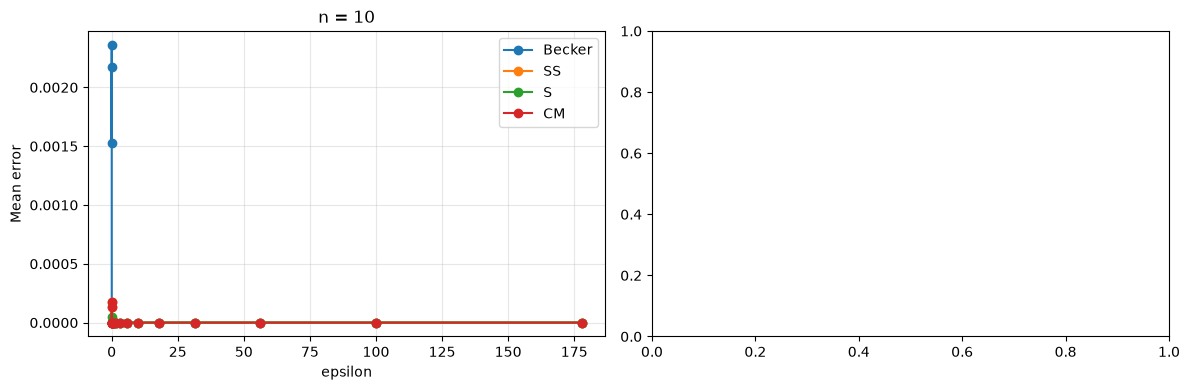

In [10]:
meta = np.load("../results/metadata.npz")
# n_list = meta["n_list"]
n_list = [10]
eps_list = meta["eps_list"]
labels = ["Becker", "SS", "S", "CM"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

print(f'\t | \t\t\t Errors when n=10 \t\t\t |')
print("-" * 90)
print(f' epsilon | \t Becker \t SS \t\t S \t\t CM \t |')
print("-" * 90)

for ax, n in zip(axes, n_list[:2]):

    errors   = np.load(f"../results/n{n}_errors.npy")    # Forma: (4, num_eps, n_iter)
    mean_errors = errors.mean(axis=2)  # Forma: (4, num_eps)

    for e_idx, eps in enumerate(eps_list):
        e1, e2, e3, e4 = mean_errors[:, e_idx]
                
        print(f"  {eps:.3f}  | \t {e1:.3f} \t\t {e2:.3f} \t\t {e3:.3f} \t\t {e4:.3f} \t |")


    for i, label in enumerate(labels):
        ax.plot(eps_list, mean_errors[i], marker="o", label=label)
        ax.set(title=f"n = {n}", xlabel="epsilon")
        ax.grid(True, alpha=0.3)


axes[0].set_ylabel("Mean error")
axes[0].legend()
fig.tight_layout()
plt.show()